# Lecture 3: Comparative Statics of the RBC Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/03_comparative_statics.ipynb)

**Economics 210A: Macroeconomics** · Johannes Wieland

In the previous lecture we specified, calibrated, log-linearized, and solved the basic real business cycle model. We are almost ready to assess how it fits the economy. Before we do, it is useful to build intuition for what the model does. We also need predictions about how the model responds to various shocks, so that we can use these predictions to test it.

This lecture derives those predictions qualitatively, using the optimality conditions, the labor market, the factor price frontier, and a **phase diagram**. Continuous time is the natural setting for a phase diagram. We study four experiments: permanent and transitory increases in government spending, and permanent and transitory increases in technology. For each, we sign the responses of the main variables on impact, during the transition, and in the long run, and then check every sign against the numerical solution of the model.

## Readings

- Barro, R. J. and R. G. King (1984), "[Time-Separable Preferences and Intertemporal-Substitution Models of Business Cycles](https://doi.org/10.2307/1883127)," *Quarterly Journal of Economics* 99(4).
- Baxter, M. and R. G. King (1993), "[Fiscal Policy in General Equilibrium](https://ideas.repec.org/a/aea/aecrev/v83y1993i3p315-34.html)," *American Economic Review* 83(3).
- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.3386/w7534)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.

## Setup

The model code is in [`code/rbc_ct.py`](../code/rbc_ct.py) (from Lecture 2, extended with step-shaped shocks in `rbc.irf_step`). The phase diagrams, labor-market diagrams and sign tables are drawn by [`code/rbc_plots.py`](../code/rbc_plots.py).

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rbc_ct as rbc
import rbc_plots as rp
from bcdata import COLORS, set_plot_style

set_plot_style()
pd.set_option("display.precision", 3)

## 1. Intuition from the optimality conditions

Recall the household's optimality conditions from Lecture 2, (HH-FOC):

$$
\begin{align}
\frac{1}{C_t} &= \lambda_t \\
L_t^{1/\eta} &= \lambda_t W_t \\
\frac{\dot\lambda_t}{\lambda_t} &= \rho - r_t .
\end{align}
$$

$\lambda_t$ is the co-state (Lagrange multiplier) on the budget constraint. It is the marginal utility of wealth: the shadow value of one unit of wealth (capital). In this model, and many others, it is optimally equal to the marginal utility of consumption from the first FOC. The second FOC determines labor supply, and the third is the Euler equation.

**$\lambda_t$ is forward looking.** Integrating the Euler equation forward from $t$ to any $s > t$,

$$
\lambda_t = \lambda_s\, e^{\int_t^s (\rho - r_u)\,du}
$$

This is saying that marginal utility at $t$ is high relative to $s$ if the real interest rate path is on average above the discount rate. In this case the returns to saving are relatively high, so households optimally consume less, and therefore have higher marginal utility of consumption.

Letting $s \to \infty$,

$$
\lambda_t =
= \lim_{s\to\infty} e^{\int_t^s (\rho - r_u)\,du}\,\lambda_s = \lim_{s\to\infty} e^{\int_t^s (\rho - r_u)\,du}\,\bar{\lambda},
\tag{FWD}
$$

where we use perfect foresight and that the economy returns to steady state, hence $\lim_{s\to\infty}\lambda_s = \bar{\lambda}$.

(FWD) shows that $\lambda_t$ depends on the entire future path of interest rates and on marginal utility in the distant future. So it is reasonable to expect that **temporary** shocks move $\lambda_t$ little: they can at most affect $\lambda_t$ through the real interest rate path and not $\bar{\lambda}$. Thus, temporary shocks move consumption through **intertemporal substitution** in the RBC model, not a traditional Keynesian consumption function. The more temporary shocks are the less we would expect future real rates to move. Hence, if shocks are transitory, $\lambda_t$ is relatively stable. When shocks are permanent, the steady state $\bar{\lambda}$ itself moves, and $\lambda_t$ can move a lot.

This is essentially the **permanent income hypothesis**. Since consumption is inversely proportional to $\lambda_t$, every statement about $\lambda_t$ maps directly into consumption: consumption moves relatively little in response to temporary shocks but can move a lot in response to permanent shocks.

**Labor supply.** Now let's go back to the FOC for labor supply

$$
L_t = \lambda_t^{\eta}\,W_t^{\eta} .
\tag{LS-λ}
$$

The labor supply curve $L^s$ is upward sloping in the wage $W_t$. Movements in $\lambda_t$ are wealth effects that shift it. Since $\lambda_t$ is relatively constant after transitory shocks, $L^s$ is a relatively fixed curve: temporary shocks mostly produce movements *along* the labor supply curve rather than shifts of it.

[Barro and King (1984)](https://doi.org/10.2307/1883127) used this condition to make an important assessment of how the model fits the data. More generally, the optimality condition for labor reads

$$
U'(C_t)\,W_t = V'(L_t),
\tag{BK}
$$

where $V'(L_t)$ is the marginal disutility of labor (in our specification $V(L_t) = L_t^{1+1/\eta}/(1+1/\eta)$, so $V'(L_t) = L_t^{1/\eta}$). This intratemporal condition links consumption and labor supply, and it holds at every point in time. Over the business cycle, consumption and hours comove. When $C_t$ rises, $U'(C_t)$ falls; when $L_t$ rises, $V'(L_t)$ rises. Therefore $W_t$ **has to be very procyclical**. Consumption and leisure are both normal goods, so they typically move in the same direction (and consumption and hours in opposite directions), unless the price of leisure, the real wage, moves a lot.

In the data, real wages are only weakly procyclical (Lecture 1). So this bare-bones closed-economy model is likely to have trouble matching the weak procyclicality of wages. The result relies on:
1. time separability of the utility function;
2. the representative-household paradigm;
3. free choice of consumption and hours over the cycle.

**Labor demand.** From the firm's problem, Lecture 2, (LD):

$$
W_t = MPL_t = (1-\alpha)\,Z_t L_t^{-\alpha}K_t^{\alpha} = (1-\alpha)\,Z_t\left(\frac{K_t}{L_t}\right)^{\alpha},
$$

a downward-sloping labor demand curve $L^d$. Labor market equilibrium requires

$$
(1-\alpha)\,Z_t\left(\frac{K_t}{L_t}\right)^{\alpha} = W_t = \frac{L_t^{1/\eta}}{\lambda_t} = L_t^{1/\eta}C_t .
\tag{LME}
$$

Holding $K_t$ and $Z_t$ constant, (LME) implies a negative relationship between hours and consumption: when $C_t$ rises, $L_t$ falls.

**Goods market.** With government purchases $G_t$, introduced in Section 2, goods market clearing reads

$$
C_t + I_t + G_t = Y_t = Z_t L_t\left(\frac{K_t}{L_t}\right)^{\alpha} .
\tag{GM}
$$

This condition will help us sign the responses of variables to shocks.

**The factor price frontier.** The firm's conditions for the two inputs give

$$
\begin{aligned}
W_t &= MPL_t = (1-\alpha)\,Z_t\left(\frac{K_t}{L_t}\right)^{\alpha}, \\
r_t + \delta &= MPK_t = \alpha\,Z_t\left(\frac{K_t}{L_t}\right)^{\alpha-1}.
\end{aligned}
\tag{FPF}
$$

Both factor prices are pinned down by two variables: technology $Z_t$ and the capital–labor ratio. A higher capital–labor ratio raises the wage and lowers the interest rate. This trade-off is the **factor price frontier**. Changes in the capital–labor ratio are movements *along* the frontier; changes in technology *shift* it. An increase in $Z_t$ lets firms pay a higher wage and a higher interest rate: the frontier shifts out.

The frontier also tells us how factor prices behave in the long run. By the Euler equation, Lecture 2, (EE), $\dot C_t/C_t = r_t - \rho$. Consumption is constant in steady state, so the steady-state interest rate is pinned down by the discount rate, $\bar r = \rho$. Shifts of the frontier due to technology can move the interest rate temporarily but not in the steady state: in the long run, changes in technology are absorbed entirely by wages.

[NOT CLEAR WHAT THE VALUE ADDED OF THE FPPF plot is]

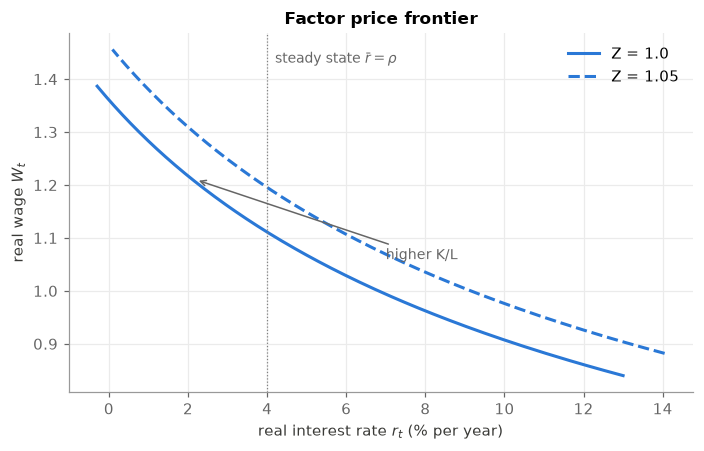

In [2]:
p = rbc.Params(sg=0.2)          # Lecture 2 calibration plus government spending (Section 2)
kl = np.linspace(2, 9, 200)     # capital-labor ratio
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for Z, ls in [(1.0, "-"), (1.05, "--")]:
    W = (1 - p.alpha) * Z * kl ** p.alpha
    r = 100 * (p.alpha * Z * kl ** (p.alpha - 1) - p.delta)
    ax.plot(r, W, ls=ls, color=COLORS["gdp"], lw=2, label=f"Z = {Z}")
ax.axvline(100 * p.rho, color="0.5", lw=0.8, ls=":")
ax.text(100 * p.rho + 0.2, 1.43, r"steady state $\bar r=\rho$", color="0.4", fontsize=9)
ax.annotate("higher K/L", xy=(2.2, 1.21), xytext=(7, 1.06), arrowprops=dict(arrowstyle="->", color="0.4"),
            color="0.4", fontsize=9)
ax.set_xlabel(r"real interest rate $r_t$ (% per year)"); ax.set_ylabel(r"real wage $W_t$")
ax.set_title("Factor price frontier"); ax.legend()
plt.tight_layout()

## 2. Derivation of the phase diagram

We work with the linearized model. Its advantage is that we can determine, locally (in the neighborhood of the steady state), the signs and slopes of the various loci and arms.

**Government spending.** Relative to the baseline model of Lecture 2, we now introduce government purchases $G_t$ explicitly. Households derive no utility from $G_t$ (it is not a public good such as national defense or navigation systems), and $G_t$ has no productive use (it does not raise technology, as research and development might). It is financed by lump-sum taxes $T_t = G_t$, so the household budget constraint becomes $\dot A_t = r_t A_t + W_t L_t - C_t - T_t$ and the goods market clears as in (GM). The steady state is as in Lecture 2, except that now $\bar C/\bar Y = 1 - \delta\alpha/(\rho+\delta) - \bar G/\bar Y$. We set $\bar G/\bar Y = 0.2$, roughly the U.S. ratio. 

Since the phase diagram has only two variables, we reduce the system to two equations, in capital $\hat k_t$ and marginal utility $\hat\lambda_t$.

**Capital.** Linearizing the goods market (GM) and solving for investment, using $\bar I = \delta\bar K$:

$$
\begin{aligned}
\hat y_t &= \frac{\bar I}{\bar Y}\hat\imath_t + \frac{\bar C}{\bar Y}\hat c_t + \frac{\bar G}{\bar Y}\hat g_t \\
\hat\imath_t &= \frac{\bar Y}{\bar I}\hat y_t - \frac{\bar C}{\bar I}\hat c_t - \frac{\bar G}{\bar I}\hat g_t \\
\hat\imath_t &= \frac{1}{\delta}\frac{\bar Y}{\bar K}\hat y_t - \frac{1}{\delta}\frac{\bar C}{\bar K}\hat c_t - \frac{1}{\delta}\frac{\bar G}{\bar K}\hat g_t .
\end{aligned}
$$

Plugging this into the linearized capital accumulation equation from Lecture 2, $\dot{\hat k}_t = \delta(\hat\imath_t - \hat k_t)$:

$$
\dot{\hat k}_t = \frac{\bar Y}{\bar K}\hat y_t - \frac{\bar C}{\bar K}\hat c_t - \frac{\bar G}{\bar K}\hat g_t - \delta\hat k_t .
$$

To eliminate output, we need hours. Combining the linearized labor supply condition from (HH-FOC) with labor demand (LD), where $\hat w_t = \hat y_t - \hat l_t = \hat z_t + \alpha\hat k_t - \alpha\hat l_t$:

$$
\begin{aligned}
\frac{1}{\eta}\hat l_t &= \hat\lambda_t + \hat w_t \\
\frac{1}{\eta}\hat l_t &= \hat\lambda_t + \hat z_t + \alpha\hat k_t - \alpha\hat l_t \\
\hat l_t &= \frac{1}{1/\eta + \alpha}\left(\hat\lambda_t + \hat z_t + \alpha\hat k_t\right).
\end{aligned}
\tag{HRS}
$$

Substituting $\hat y_t = \hat z_t + \alpha\hat k_t + (1-\alpha)\hat l_t$, (HRS) and $\hat c_t = -\hat\lambda_t$, the change in the capital stock is

$$
\dot{\hat k}_t = \frac{\bar Y}{\bar K}\left(1 + \frac{1-\alpha}{\alpha + 1/\eta}\right)\hat z_t
+ \left(\alpha\frac{\bar Y}{\bar K}\left(\frac{1-\alpha}{\alpha+1/\eta} + 1\right) - \delta\right)\hat k_t
+ \left(\frac{\bar C}{\bar K} + \frac{\bar Y}{\bar K}\frac{1-\alpha}{\alpha+1/\eta}\right)\hat\lambda_t
- \frac{\bar G}{\bar K}\hat g_t .
\tag{KDOT}
$$

We have eliminated all other endogenous variables: the change in the capital stock depends only on the capital stock, the marginal utility of wealth $\hat\lambda_t$, and the exogenous forcing variables $\hat z_t$ and $\hat g_t$.

In the steady state, the change in the capital stock is zero $\dot{\hat k}_t = 0$ and we can use this fact to find the properties of the locus of points such that the capital stock is not changing.

**Marginal utility.** Using $\hat\lambda_t = -\hat c_t$ and the linearized Euler equation from Lecture 2, $\dot{\hat c}_t = (\rho+\delta)(\hat y_t - \hat k_t)$, where $\hat y_t - \hat k_t = \widehat{MPK}_t$:

$$
\begin{aligned}
\dot{\hat\lambda}_t &= -(\rho+\delta)\,\widehat{MPK}_t \\
&= -(\rho+\delta)\left(\hat z_t + (\alpha - 1)\hat k_t + (1-\alpha)\hat l_t\right) \\
&= -(\rho+\delta)\left(\hat z_t + (\alpha - 1)\hat k_t + \frac{1-\alpha}{1/\eta+\alpha}\left(\hat\lambda_t + \hat z_t + \alpha\hat k_t\right)\right),
\end{aligned}
$$

where the last step uses (HRS). Collecting terms,

$$
\dot{\hat\lambda}_t = -(\rho+\delta)\left[\left(1 + \frac{1-\alpha}{1/\eta+\alpha}\right)\hat z_t + (1-\alpha)\left(\frac{\alpha}{1/\eta+\alpha} - 1\right)\hat k_t + \frac{1-\alpha}{1/\eta+\alpha}\hat\lambda_t\right].
\tag{LDOT}
$$

This is the law of motion of the marginal utility of wealth. Note that it does not depend directly on government spending (why?). (KDOT) and (LDOT) are the linear system (LIN) of Lecture 2, now with $\hat g_t$.

Setting $\dot{\hat\lambda}_t = 0$ gives the loci along which marginal utility do not change. The intersection with the $\dot{\hat k}_t = 0$ locus is the steady state.

**Locus $\dot{\hat k}_t = 0$.** From (KDOT):

$$
\hat\lambda_t = -\frac{1}{\frac{\bar C}{\bar K} + \frac{\bar Y}{\bar K}\frac{1-\alpha}{\alpha+1/\eta}}
\left[\frac{\bar Y}{\bar K}\left(1 + \frac{1-\alpha}{\alpha+1/\eta}\right)\hat z_t
+ \left(\alpha\frac{\bar Y}{\bar K}\left(\frac{1-\alpha}{\alpha+1/\eta}+1\right) - \delta\right)\hat k_t
- \frac{\bar Y}{\bar K}\hat g_t\right].
\tag{$\dot K$-locus}
$$

Because $\alpha\frac{\bar Y}{\bar K}\left(\frac{1-\alpha}{\alpha+1/\eta}+1\right) - \delta > 0$ (recall $\alpha\bar Y/\bar K = \rho + \delta > \delta$), the locus is **downward sloping**. On this locus, consumption, labor and investment are such that the current capital stock is just maintained. It slopes down because with less capital, and thus less output, consumption must fall (and hours rise) to maintain the same capital stock.

**Locus $\dot{\hat\lambda}_t = 0$.** From (LDOT):

$$
\hat\lambda_t = -\frac{1/\eta+\alpha}{1-\alpha}\left[\left(1 + \frac{1-\alpha}{1/\eta+\alpha}\right)\hat z_t + (1-\alpha)\left(\frac{\alpha}{1/\eta+\alpha} - 1\right)\hat k_t\right].
\tag{$\dot\lambda$-locus}
$$

This locus is **upward sloping** because $(1-\alpha)\left(\frac{\alpha}{1/\eta+\alpha} - 1\right) < 0$: $1 - \alpha > 0$ and $\frac{\alpha}{1/\eta+\alpha} < 1$. (Without technology shocks it simplifies to $\hat\lambda_t = \hat k_t/\eta$.) On this locus, consumption and hours are such that the real interest rate and the MPK equal their steady-state values. By the Euler equation (EE), $\dot C_t/C_t = r_t - \rho$, so consumption and marginal utility are constant only if $r_t = MPK_t - \delta = \rho$. The locus slopes up because a higher capital stock lowers the MPK, while a higher marginal utility raises labor supply and thus the MPK. On the locus the two forces exactly balance.

In [3]:
A, B = rbc.linear_system(p)
ss = rbc.steady_state(p)
YK, CK, a, eta = ss["Y"] / ss["K"], ss["C"] / ss["K"], p.alpha, p.eta
phi = 1 / (1 / eta + a)
A_kdot = [a * YK * ((1 - a) * phi + 1) - p.delta, CK + YK * (1 - a) * phi]        # (KDOT): k, lambda
B_kdot = [YK * (1 + (1 - a) * phi), -YK]                                           # (KDOT): z, g
A_ldot = [-(p.rho + p.delta) * (1 - a) * (a * phi - 1), -(p.rho + p.delta) * (1 - a) * phi]   # (LDOT)
B_ldot = [-(p.rho + p.delta) * (1 + (1 - a) * phi), 0.0]
print("max |(KDOT),(LDOT) - linear_system|:",
      np.abs(np.array([A_kdot, A_ldot]) - A).max(), np.abs(np.array([B_kdot, B_ldot]) - B).max())
print(f"slope of K-locus = {-A[0,0]/A[0,1]:.3f} < 0,   slope of lambda-locus = {-A[1,0]/A[1,1]:.3f} = 1/eta > 0")

max |(KDOT),(LDOT) - linear_system|: 0.0 0.0
slope of K-locus = -0.258 < 0,   slope of lambda-locus = 1.000 = 1/eta > 0


### 2.1 Variables in the phase diagram

$K_t$ is given by history: it cannot jump at the time of a shock. $\lambda_t$ is forward looking: it can jump. The phase diagram therefore has two arms, one stable and one unstable. The stable arm runs from the north-west, above both loci, to the steady state, and from the south-east, below both loci, to the steady state. The unstable arm runs from the north-west, above the $\dot{\hat\lambda}_t = 0$ locus and below the $\dot{\hat k}_t = 0$ locus, through the steady state to the south-east.

The stable arm gives the optimal choice of $\hat\lambda_t$ for a given capital stock. All other choices of $\hat\lambda_t$, above or below the stable arm, produce explosive paths that eventually converge to the unstable arm. If $\hat\lambda_t$ is too low (consumption too high), the economy moves towards the bottom left, eventually running out of capital and thus of any potential for consumption. Above the stable arm, the household consumes too little ($\hat\lambda_t$ too high) and accumulates an ever larger capital stock. This violates the transversality condition: the household would have higher welfare by consuming more today.

Along the stable arm the economy converges gradually towards the steady state, at the rate of the stable eigenvalue $|\mu_s|$ (Lecture 2, (SA)). The distance to the steady state shrinks at a constant proportional rate, so investment is highest (in absolute terms) when the economy is furthest from the steady state. The figure shows the economy starting with 10% too little capital: it begins at $A$ on the stable arm and converges to the steady state $B$.

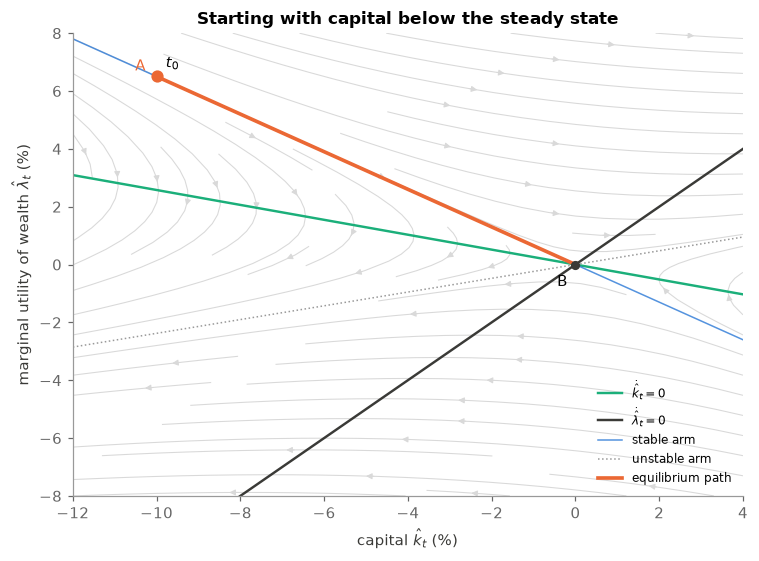

In [4]:
path = rbc.irf(p, k0=-0.10, T=40, n=801)
fig, ax = plt.subplots(figsize=(7, 5.2))
rp.phase_diagram(ax, p, path=path, lim=(-12, 4, -8, 8))
ax.annotate("A", (path["K"].iloc[0], path["lambda"].iloc[0]), xytext=(-14, 4), textcoords="offset points", color=rp.PATH)
ax.annotate("B", (0, 0), xytext=(-12, -14), textcoords="offset points")
ax.set_title("Starting with capital below the steady state"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

### 2.2 Shifts of the loci after shocks

Using the linearized system, we can see right away what happens to the steady state after a permanent shock to technology or government spending. An increase in technology shifts **both** loci down. Therefore $\bar\lambda$ unambiguously falls. What happens to $\bar K$ depends on which locus shifts more.

When government spending increases, only the $\dot{\hat k}_t = 0$ locus shifts, and it shifts **up**. Thus the steady-state values of both $\bar\lambda$ and $\bar K$ increase.

In what follows we examine the responses of the variables at the time of the shock (**impact**), on the path to the new or old steady state (**transition**), and once the system has converged (**steady state**). The shock hits unexpectedly at $t_0 = 0$.

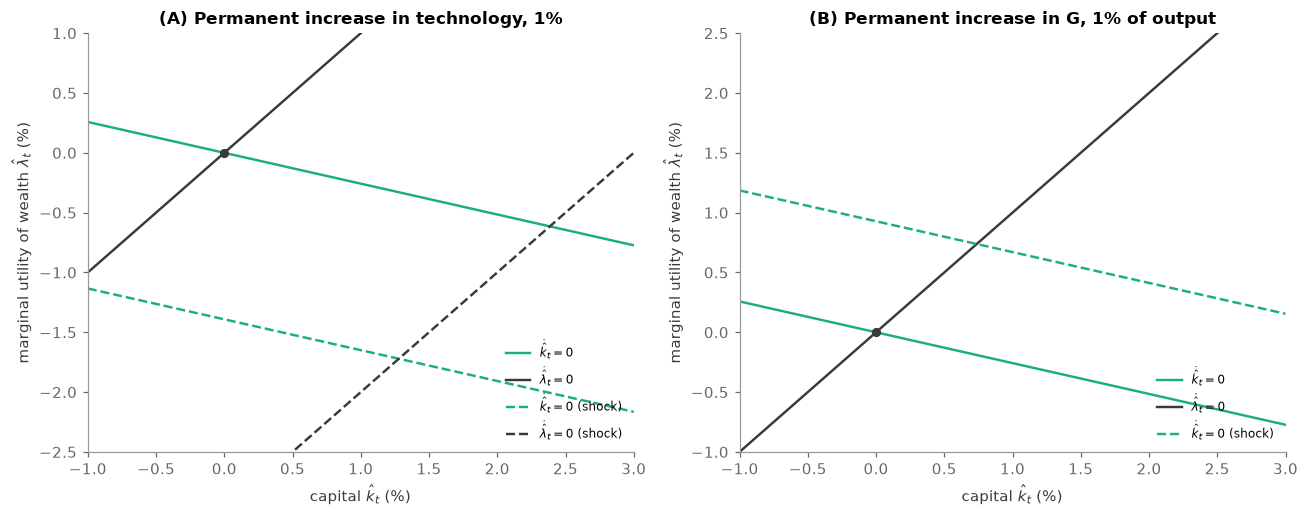

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
rp.phase_diagram(axes[0], p, z_new=0.01, g_new=0.0, lim=(-1, 3, -2.5, 1), arms=False, field=False)
axes[0].set_title("(A) Permanent increase in technology, 1%")
rp.phase_diagram(axes[1], p, z_new=0.0, g_new=0.01, lim=(-1, 3, -1, 2.5), arms=False, field=False)
axes[1].set_title("(B) Permanent increase in G, 1% of output")
for ax in axes:
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

## 3. Response to a permanent government-spending shock

We start with an easy case: a permanent, unanticipated increase in government spending at $t_0$, by 1% of output. Remember what this shock entails: the government throws away output and taxes the household (lump sum) to pay for it. Think of wars on foreign territory, not investment in roads or schools, which we would have to model very differently. We collect the qualitative predictions in a table.

**Impact.** From the phase diagram, the $\dot{\hat k}_t = 0$ locus shifts up. The new steady state has a higher $\lambda$ and a higher capital stock $K$. Capital is predetermined and does not move at the time of the shock (0 in the table), so on impact the only variable in the diagram that can react is $\lambda$. To put the economy on the stable arm, so that it converges to the new steady state, $\lambda$ has to jump **up** to the new stable arm. From the optimality condition for consumption, consumption and $\lambda$ are inversely related, so consumption **falls** on impact.

In the labor market (second panel), $K$ is fixed on impact and technology does not change, so the marginal product of labor does not change: $L^d$ does not move. From the optimality condition for labor supply, a higher $\lambda$ makes the household supply more labor at any given wage, because an additional unit of work is more valuable. Labor supply $L^s$ shifts down (out). The labor market clears with $W$ **lower** and $L$ **higher**.

With technology and capital fixed and hours higher, output **rises** on impact (production function). So consumption falls while output and government spending rise. This combination of signs means we cannot use the goods market (GM) to sign investment: we do not know whether the change in output is large or small relative to $C + G$. We look at the phase diagram instead. Capital is predetermined, but investment is not. The change in capital is largest at the time of the shock: as we move along the stable arm, the increments in capital become smaller and smaller. Therefore investment jumps **up** on impact and then gradually declines.

Finally, we sign the interest rate using the factor price frontier (FPF). With no change in technology, any changes in wages and the interest rate occur along the frontier. Since the wage falls, the interest rate **rises**.

**Transition.** We now sign changes along the transition path *relative to the values right after the shock*, at $t_0$. A "decrease" therefore does not mean that a variable is below its initial steady-state value if it jumped up at $t_0$. From the phase diagram, $\lambda$ falls while capital rises. A falling $\lambda$ means rising consumption. Investment falls along the transition, as argued above. In the labor market, a falling $\lambda$ shifts labor supply back up (in), while a rising capital stock shifts labor demand up. The wage rises unambiguously, and from the factor price frontier the interest rate falls. What happens to hours and output is ambiguous: both labor demand and supply shift up, so the movement in hours depends on the relative strength of the shifts. Because hours are ambiguous, the production function cannot sign output. Neither can the goods market, because consumption rises while investment falls. Thus we put "?" in the $L$ and $Y$ rows.

**Steady state.** From the phase diagram, capital and $\lambda$ are higher, so consumption is lower. From the capital accumulation equation, $\bar I = \delta\bar K$, so investment is higher too. The factor price frontier does not move, and the steady-state interest rate is pinned down by the discount rate, $\bar r = \rho$. Therefore neither the interest rate nor the wage changes. But since capital is higher, the same factor prices are possible only if hours rise in proportion, keeping the capital–labor ratio constant. Thus hours are higher in the new steady state, and by the production function output is higher too.

| | Impact $t = t_0$ | Transition $t \in (t_0, \infty)$ | Steady state $t = \infty$ |
|---|:-:|:-:|:-:|
| $\lambda$ | ↑ | ↓ | ↑ |
| $K$ | 0 | ↑ | ↑ |
| $C$ | ↓ | ↑ | ↓ |
| $L$ | ↑ | ? | ↑ |
| $Y$ | ↑ | ? | ↑ |
| $I$ | ↑ | ↓ | ↑ |
| $W$ | ↓ | ↑ | 0 |
| $r$ | ↑ | ↓ | 0 |

The figures show the phase diagram, the labor market on impact, and the impulse responses of the model. The table below them reports the signs computed from the numerical solution: they match every entry above and resolve the "?" for our calibration.

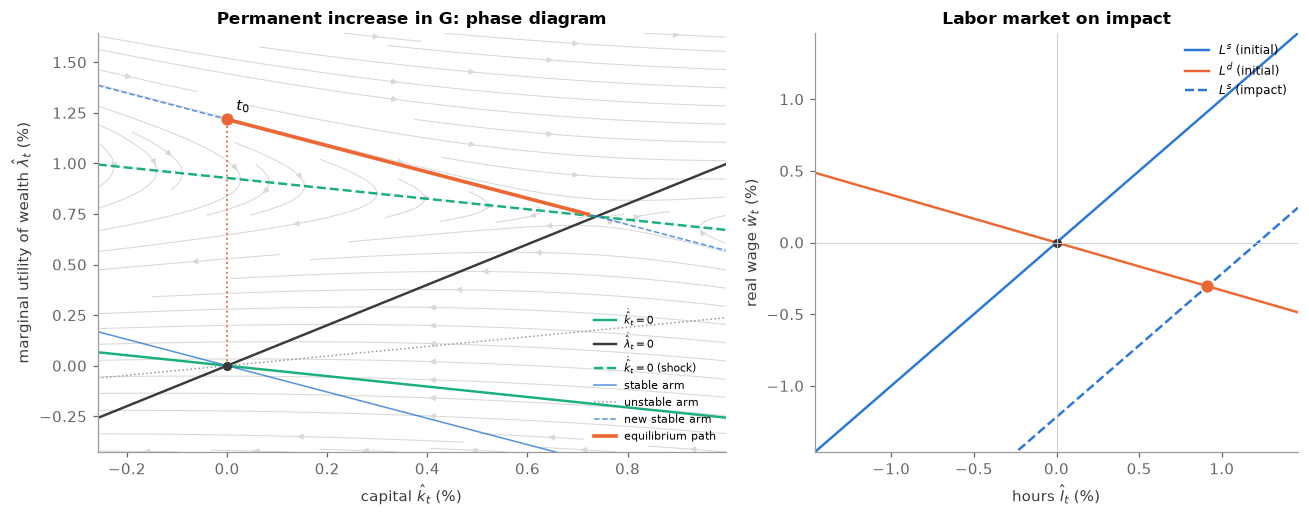

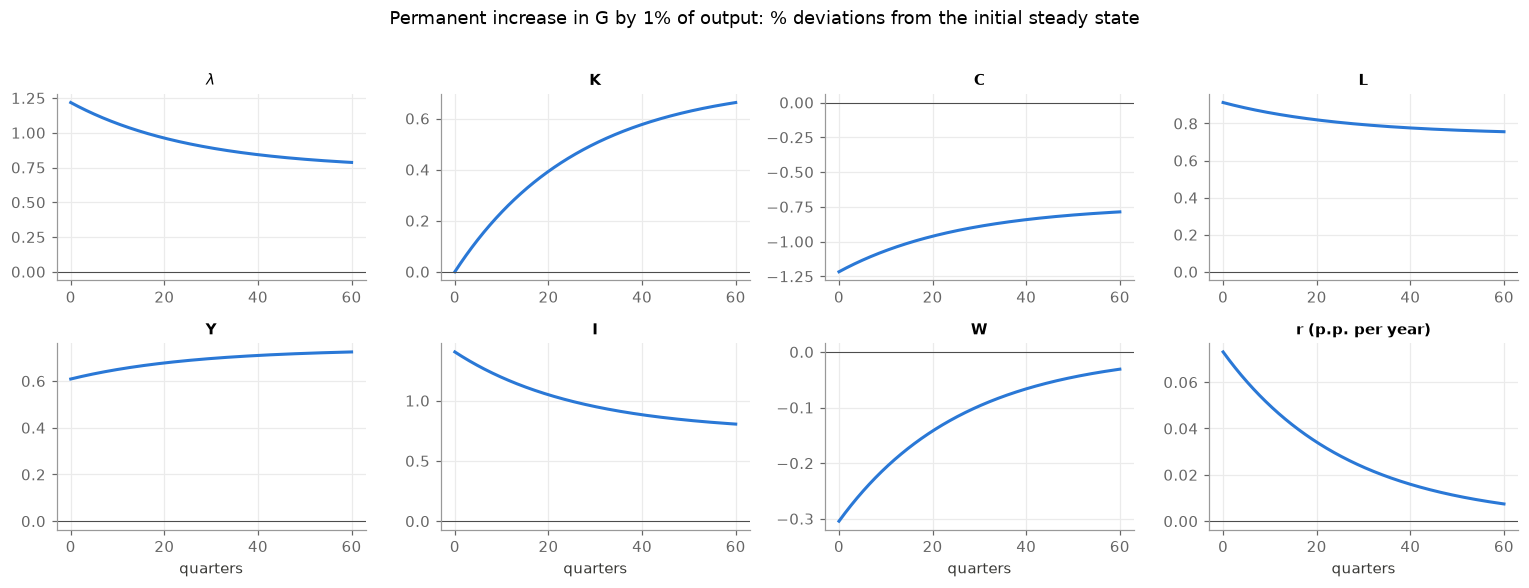

In [6]:
g0 = 0.01
path = rbc.irf_step(p, g0=g0, T=25, n=1001)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
rp.phase_diagram(axes[0], p, z_new=0.0, g_new=g0, path=path)
axes[0].set_title("Permanent increase in G: phase diagram"); axes[0].legend(loc="lower right", fontsize=7)
rp.labor_market(axes[1], p, path, t=0.0)
axes[1].set_title("Labor market on impact"); axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
rp.irf_panel(path, "G")
plt.suptitle("Permanent increase in G by 1% of output: % deviations from the initial steady state", y=1.02)
plt.tight_layout()

In [7]:
rp.sign_table(rbc.irf_step(p, g0=g0, T=400, n=8001))

,impact,transition,steady state
λ,↑,↓,↑
K,0,↑,↑
C,↓,↑,↓
L,↑,↓,↑
Y,↑,↑,↑
I,↑,↓,↑
W,↓,↑,0
r,↑,↓,0


**Why does the household behave this way?** The government throws away resources and taxes the household for the rest of time. The household is worse off: it cannot maintain its original consumption and leisure. It has three ways to respond and still satisfy its budget (resource) constraint: reduce consumption, increase labor supply, and/or reduce investment (draw on savings). All of these margins are costly. Here the household uses the first two. How much of each depends on parameters: if raising labor supply is not very costly (the Frisch elasticity is high), the household primarily uses that margin; if raising labor supply is very costly, it lowers consumption more.

The phase diagram also shows that the economy in fact *accumulates* capital. Why does the household not use the third margin? Because the long-run increase in labor supply makes capital more valuable: for a given capital stock, higher hours raise the marginal product of capital, and thus the return on saving and investing. Suppose instead that the household kept capital constant (the argument is even stronger for eating into it). Then the real interest rate would be permanently higher, $\tilde r > \rho$, where $\tilde X$ denotes variable $X$ on this alternative path. From the Euler equation (EE), $\tilde C_t = e^{-(\tilde r - \rho)(s - t)}\tilde C_s$ for any $s > t$, so $\tilde C_t = \lim_{s\to\infty} e^{-(\tilde r-\rho)(s-t)}\tilde C_s$. If long-run consumption is finite, consumption today is zero. The incentive to save is just too strong. This contradicts our premise that investment does not rise: if consumption is zero, income is saved and invested. Suppose instead that long-run consumption is infinite. With a constant, finite capital stock, infinite consumption is infeasible unless hours are infinite, which is not optimal either, because the disutility of labor rises faster than the utility of consumption. In short, the rise in labor supply raises the marginal product of capital, which gives the household an incentive to accumulate capital.

The incentive to save is particularly strong on impact. At $t_0$ the marginal product of capital, $MPK_t = \alpha Z_t K_t^{\alpha-1}L_t^{1-\alpha}$, is very high, because hours have risen a lot while capital is fixed. From the Euler equation, $\dot{\hat c}_t = (\rho+\delta)\widehat{MPK}_t$, the higher the interest rate, the faster consumption grows. So consumption and marginal utility converge to the steady state at a pace commensurate with the real interest rate, and the pace slows as the interest rate declines. From the phase diagram, investment slows too as capital and consumption approach the steady state. Intuitively, investment is most valuable when the marginal product of capital is highest, which is at $t_0$. As capital accumulates, the real interest rate declines, and so do the incentives to save and invest.

These predictions lead to an important conclusion. In the basic RBC model, **consumption and output move in opposite directions** after a permanent government spending shock. This contradicts a key empirical regularity: consumption and output comove over the business cycle (Lecture 1). Shocks like government spending therefore cannot be the main driving force of business cycles: if they were, we would observe a negative correlation between output and consumption.

## 4. Response to a transitory government-spending shock

Permanent government spending shocks produce responses inconsistent with the comovement of macroeconomic variables in the data. Do unanticipated *transitory* shocks to government spending fit the data better? We assume that $G$ increases at $t_0$ and stays high until $t_1$, when it returns to its initial level. Everyone knows that spending returns to its initial level at $t_1$: the change at $t_1$ is perfectly anticipated. In the figures, $t_1 - t_0$ is two years.

Since the shock is temporary, the economy returns to the initial steady state, and the loci are back in their original positions in the long run: we can put 0 in the last column of the table. For $t \in [t_0, t_1)$, however, the economy is governed by the $\dot{\hat k}_t = 0$ locus shifted up. We know that $\lambda$ jumps up after a permanent increase in government spending, to put the economy on the stable arm. After a transitory shock, $\lambda$ also jumps up, **but by less**. Intuitively, the economy has to be on the stable arm only at $t_1$, when the shock ends. Between $t_0$ and $t_1$ it follows an explosive path of the shifted dynamics, chosen so that it reaches the original stable arm precisely at $t_1$. This explosive path lies below the stable arm for the permanent shock, so the jump in $\lambda$ is smaller. (Recall that transitory shocks affect marginal utility relatively little, because it is forward looking.) For now we consider the case in which $\lambda$ jumps to a value *below* the new $\dot{\hat k}_t = 0$ locus. As we argue below, this is the case when the shock is relatively transitory. As after a permanent shock, $\lambda$ falls for all $t \in (t_0, \infty)$, so its qualitative dynamics are the same.

The dynamics of capital, in contrast, are different. After a permanent shock, the economy accumulates capital to support the higher spending. After a transitory shock, capital **falls** for $t \in (t_0, t_1)$ and rises back to its initial level for $t \in (t_1, \infty)$. The economy "eats" its capital stock, its only form of saving, while spending is high. Capital does not jump at $t_1$, because it is predetermined. We can infer investment from the dynamics of capital, since investment is effectively the time derivative of capital. On impact, investment jumps **down**, since capital starts to fall. What happens along the explosive path may depend on parameters (how long the shock lasts), but here investment keeps declining: over $(t_0, t_1)$, consumption rises while output falls and $G_t$ is constant, so the only way the goods market (GM) can clear is if investment declines further. Over $(t_0, t_1)$ the economy eats more and more of its capital stock.

At $t_1$, capital changes direction: it starts to rise. Hence investment jumps **up**. On the stable arm, capital accumulation slows as the economy approaches the steady state, so investment falls relative to its value at $t_1$.

**Labor market.** On impact, labor supply shifts out while labor demand does not move (neither capital nor technology changes). Hours rise and the wage falls. Since hours rise, the production function tells us that output rises at $t_0$.

Between $t_0$ and $t_1$, $\lambda$ falls, so labor supply shifts back in. At the same time capital falls, so labor demand shifts down. Hours unambiguously fall relative to their level at $t_0$, but the labor market alone cannot sign the wage. The factor price frontier does not help either: both capital and hours fall, so we do not know what happens to the capital–labor ratio. From the Euler equation, consumption growth is proportional to $r_t - \rho$; consumption rises monotonically between $t_0$ and $t_1$, so the interest rate is above its steady-state value. But to sign the *change* in the interest rate we would need to know the acceleration of consumption, which along the explosive path depends on many factors. So the predictions for the interest rate and wages are ambiguous ("?").

At $t_1$, $\lambda$ does not jump, so we record no change in $\lambda$ and consumption. Capital is fixed (it is at its turning point), so labor demand does not move. Since neither labor supply nor labor demand moves, there is no change in wages, hours, output (production function), or the interest rate (factor price frontier). The end of the spending shock might suggest a fall in output via the goods market. But the fall in government spending is exactly offset by a jump up in investment, so output does not change.

On the stable arm, $t \in (t_1, \infty)$, consumption keeps rising as $\lambda$ falls. Labor supply keeps shifting in, and labor demand starts shifting up as the economy accumulates capital. Wages rise unambiguously, and from the factor price frontier the interest rate falls. Hours are ambiguous, because the outcome depends on the relative strength of the shifts. So the production function cannot sign output, and neither can the goods market, since consumption rises while investment falls.

| | Impact $t = t_0$ | Transition I $t \in (t_0, t_1)$ | Inflection $t = t_1$ | Transition II $t \in (t_1, \infty)$ | Steady state $t = \infty$ |
|---|:-:|:-:|:-:|:-:|:-:|
| $\lambda$ | ↑ | ↓ | 0 | ↓ | 0 |
| $K$ | 0 | ↓ | 0 | ↑ | 0 |
| $C$ | ↓ | ↑ | 0 | ↑ | 0 |
| $L$ | ↑ | ↓ | 0 | ? | 0 |
| $Y$ | ↑ | ↓ | 0 | ? | 0 |
| $I$ | ↓ | ↓ | ↑ | ↓ | 0 |
| $W$ | ↓ | ? | 0 | ↑ | 0 |
| $r$ | ↑ | ? | 0 | ↓ | 0 |

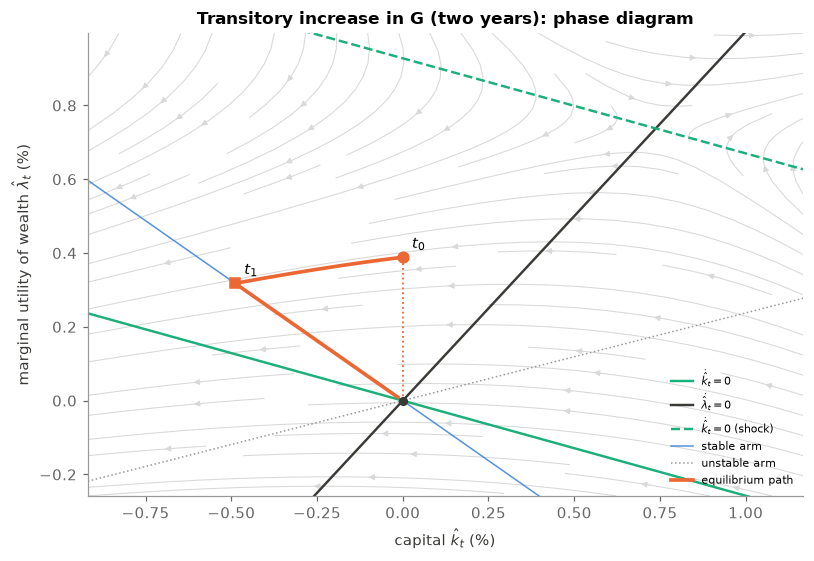

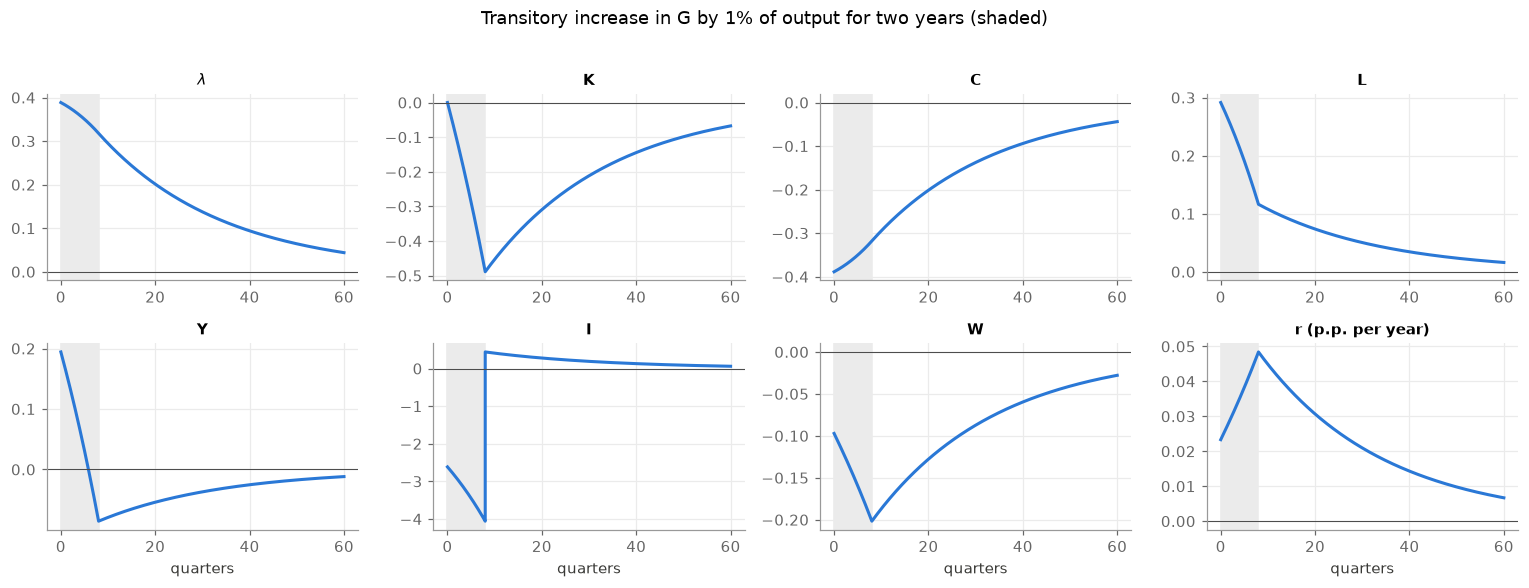

In [8]:
t1 = 2.0                                       # shock lasts two years
path = rbc.irf_step(p, g0=g0, t1=t1, T=25, n=1001)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
rp.phase_diagram(ax, p, z_new=0.0, g_new=g0, path=path, t1=t1)
ax.set_title("Transitory increase in G (two years): phase diagram"); ax.legend(loc="lower right", fontsize=7)
plt.tight_layout()
rp.irf_panel(path, "G", t1=t1)
plt.suptitle("Transitory increase in G by 1% of output for two years (shaded)", y=1.02)
plt.tight_layout()

In [9]:
rp.sign_table(rbc.irf_step(p, g0=g0, t1=t1, T=400, n=8001), t1=t1)

,impact,transition I,at t1,transition II,steady state
λ,↑,↓,0,↓,0
K,0,↓,0,↑,0
C,↓,↑,0,↑,0
L,↑,↓,0,↓,0
Y,↑,↓,0,↑,0
I,↓,↓,↑,↓,0
W,↓,↓,0,↑,0
r,↑,↑,0,↓,0


In some respects the economy behaves as after a permanent shock: consumption falls, labor supply rises, and output rises. Again the household responds to being poorer by consuming less and working more. But investment and capital behave very differently: they rose after a permanent shock and fall after a temporary one. Why? A permanent shock raises the value of capital, because it permanently raises labor supply. With a temporary shock there is no long-run benefit from a larger capital stock, because in the long run labor supply returns to normal. The return to investment therefore rises less when the shock is temporary than when it is permanent, all else equal, so investment must rise less than in the permanent case.

But here investment did not just rise less; it declined. Integrating the Euler equation, $\dot{\hat c}_t = r_t - \rho$, forward gives today's consumption response:

$$
\hat c_t = -\int_t^\infty \left(r_s - \rho\right) ds + \underbrace{\lim_{s\to\infty}\hat c_s}_{=\,0 \text{ for a temporary shock}} .
$$

If the interest rate (the marginal product of capital) does not rise much, consumption falls relatively little. From the resource constraint (GM), $Y_t = C_t + I_t + G_t$, the household then uses investment to absorb the spending shock. Intuitively, for a shock that goes away quickly, it is not optimal to give up consumption to accumulate long-lasting capital, which will not be valuable for very long. The household achieves a higher consumption path by eating into the capital stock while the shock lasts and rebuilding it once the shock is over. (You can check that our proof by contradiction for the permanent shock no longer works when the shock is temporary.)

The argument also suggests that for a shock that is temporary but very persistent, it may still make sense to accumulate some capital, though less than after a permanent shock. The more persistent the shock, the longer labor supply is elevated and the longer the marginal product of capital is high. Indeed, this happens when the shock is so persistent that $\lambda_{t_0}$ lies **above** the new $\dot{\hat k}_t = 0$ locus. The next figure shows this case for a shock lasting ten years. The main changes concern investment on impact (it now rises) and the transition of investment and capital. As the shock becomes ever more persistent, the economy's behavior approaches that of the permanent shock. Note, though, that the household would never optimally choose a point above the stable arm of the permanent shock: transitory shocks have smaller effects on marginal utility than permanent shocks.

Even when government spending shocks are very persistent, consumption and output still move in opposite directions. So our conclusion regarding the business cycle facts is unchanged.

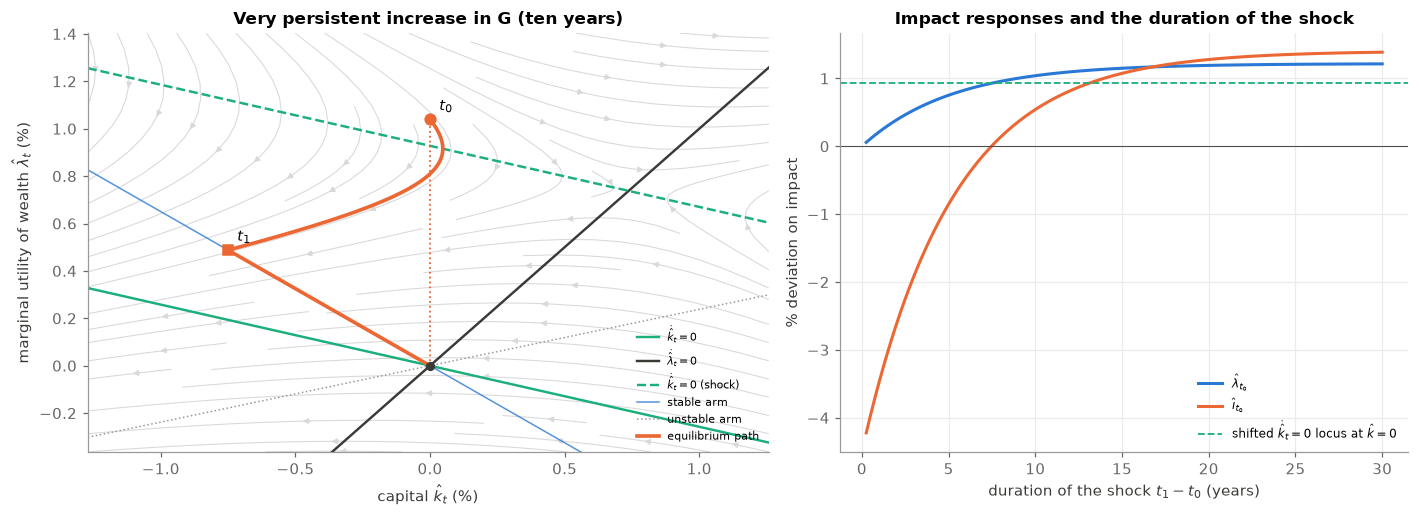

In [10]:
t1_long = 10.0
path_long = rbc.irf_step(p, g0=g0, t1=t1_long, T=40, n=1601)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
rp.phase_diagram(axes[0], p, z_new=0.0, g_new=g0, path=path_long, t1=t1_long)
axes[0].set_title("Very persistent increase in G (ten years)"); axes[0].legend(loc="lower right", fontsize=7)
# impact lambda and investment as a function of the duration of the shock
durations = np.linspace(0.25, 30, 120)
lam0 = [rbc.irf_step(p, g0=g0, t1=d, T=d + 1, n=50)["lambda"].iloc[0] for d in durations]
inv0 = [rbc.irf_step(p, g0=g0, t1=d, T=d + 1, n=50)["I"].iloc[0] for d in durations]
locus = 100 * rbc.loci(p, 0.0, 0.0, g0)[0]
axes[1].plot(durations, lam0, color=COLORS["gdp"], lw=2, label=r"$\hat\lambda_{t_0}$")
axes[1].plot(durations, inv0, color=COLORS["series"], lw=2, label=r"$\hat\imath_{t_0}$")
axes[1].axhline(locus, color=rp.LOCUS_K, ls="--", lw=1.2, label=r"shifted $\dot{\hat k}_t=0$ locus at $\hat k=0$")
axes[1].axhline(0, color="0.3", lw=0.7)
axes[1].set_xlabel(r"duration of the shock $t_1 - t_0$ (years)"); axes[1].set_ylabel("% deviation on impact")
axes[1].set_title("Impact responses and the duration of the shock"); axes[1].legend(fontsize=8)
plt.tight_layout()

The right panel shows the threshold: impact investment turns positive exactly when $\hat\lambda_{t_0}$ crosses the shifted $\dot{\hat k}_t = 0$ locus, at a duration of about seven and a half years in our calibration.

To see why investment must jump at $t_1$ on an optimal path, note that the household wants smooth consumption and smooth labor supply. If those variables follow continuous paths, as they do at the optimum, then, with capital predetermined, output $Y_t = Z_t K_t^\alpha L_t^{1-\alpha}$ is continuous too. In the resource constraint (GM), the only variable that can then jump at $t_1$ is investment. It exactly offsets the decline in $G_t$ at that instant.

In summary, temporary spending shocks are also a problematic source of business cycles. Consumption, and now investment too, move opposite to hours and output, which is inconsistent with the data. Temporary government spending shocks cannot be the main source of business cycles in this class of models. The analysis also highlights the role of capital in smoothing out and propagating shocks: households use capital, their only form of saving, to smooth a temporary shock.

## 5. Response to a permanent technology shock

Now we turn to the other source of fluctuations in the model: technology. To understand the responses, we again use the phase diagram, the labor market, and the factor price frontier. We start with a permanent, unanticipated 1% increase in technology at $t_0$. Since both loci shift, there are several possibilities for where the new steady state lies. We focus on the case in which $\bar\lambda$ **is lower** and $\bar K$ **is higher** after the shock, and in which the new stable arm lies **below the original steady state**. This is the case in our calibration.

**Impact.** Given our assumptions about the new steady state, $\lambda$ has to jump **down** on impact to put the economy on the new stable arm. A lower $\lambda$ means higher consumption. Capital does not change at the time of the shock, because it is predetermined. Since capital is higher in the new steady state, investment jumps **up** as the economy starts to accumulate capital.

In the labor market (second panel), labor demand shifts up (technology raises the MPL) and labor supply shifts in (workers feel richer as $\lambda$ falls). Wages rise unambiguously, but we cannot sign the change in hours. Because of this ambiguity, the production function cannot sign output. The goods market can: consumption and investment both rise at $t_0$, so output rises on impact. We sign the interest rate below, once we understand the dynamics of the other variables.

**Transition.** Along the transition path, $\lambda$ falls, $K$ rises, and consumption rises (relative to their values at $t_0$). Because capital rises at a decreasing rate, investment falls relative to its level at $t_0$. A falling $\lambda$ keeps shifting labor supply in; a rising capital stock keeps shifting labor demand up. Wages rise, but again we cannot sign hours. Investment falls and consumption rises, so the goods market cannot sign output, and neither can the production function, since hours are ambiguous. In general we cannot sign output during the transition, but in plausible parameterizations it rises.

**Steady state.** Capital is higher and $\lambda$ lower (by our assumptions) than in the initial steady state. Hence consumption is higher, and investment is higher ($\bar I = \delta\bar K$). Wages are higher, as the factor price frontier has shifted out while $\bar r = \rho$. Since consumption and investment are both higher, output is higher too.

**Interest rate.** A higher wage does not imply a lower interest rate here, because the factor price frontier shifts out: both a higher wage and a higher interest rate can be sustained. But we can use "backward induction". The steady-state interest rate is pinned down by the discount rate, so even though the frontier shifts, the interest rate is the same in the new steady state. The economy converges monotonically to the new steady state after the shock, with wages jumping up at $t_0$ and rising afterwards. Moving along the new frontier, the interest rate must therefore approach its steady-state level from above. So the interest rate jumps **up** on impact and then falls during the transition.

In contrast to spending shocks, technology shocks generate **comovement** of macroeconomic variables like that in the data. At least within this basic model, we can make the model consistent with the data only if technology shocks are the primary source of fluctuations.

| | Impact $t = t_0$ | Transition $t \in (t_0, \infty)$ | Steady state $t = \infty$ |
|---|:-:|:-:|:-:|
| $\lambda$ | ↓ | ↓ | ↓ |
| $K$ | 0 | ↑ | ↑ |
| $C$ | ↑ | ↑ | ↑ |
| $L$ | ? | ? | ? |
| $Y$ | ↑ | ↑ (generally) | ↑ |
| $I$ | ↑ | ↓ | ↑ |
| $W$ | ↑ | ↑ | ↑ |
| $r$ | ↑ | ↓ | 0 |

In our calibration hours rise on impact, fall during the transition, and end slightly *below* their initial level. The last result arises because $\bar G$ is fixed in levels: as income rises, the tax burden falls relative to income, and the wealth effect lowers labor supply (with $\bar G = 0$, hours would return exactly to their initial level, as the steady-state formula for $\bar L$ in Lecture 2 shows).

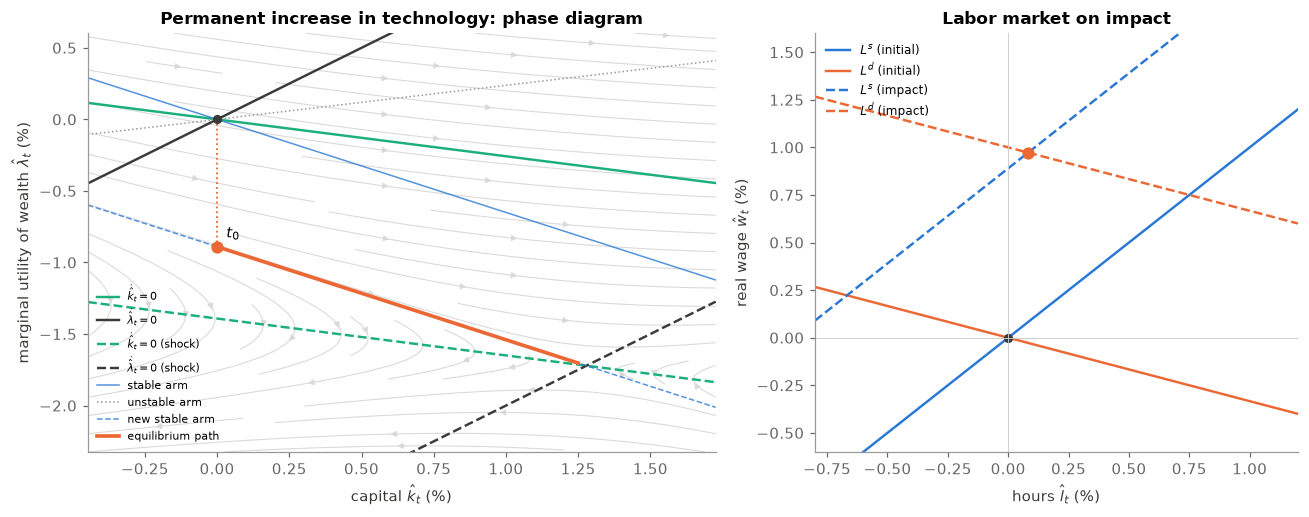

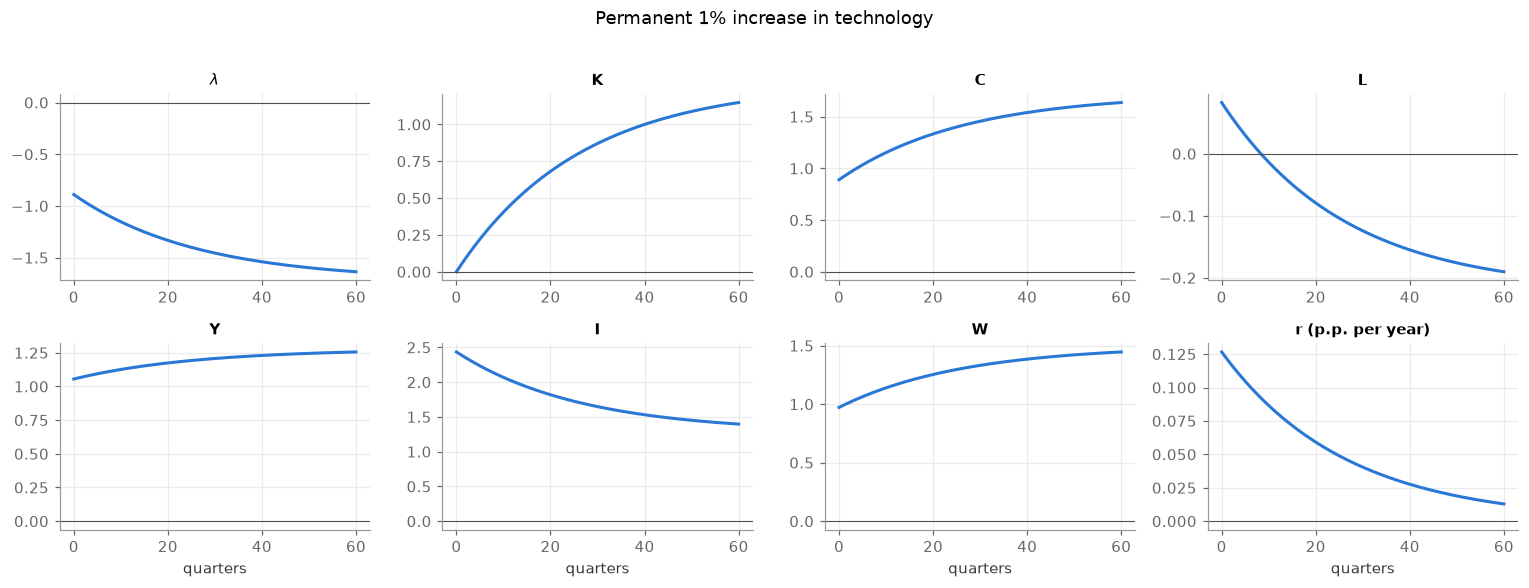

In [11]:
z0 = 0.01
path = rbc.irf_step(p, z0=z0, T=25, n=1001)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
rp.phase_diagram(axes[0], p, z_new=z0, g_new=0.0, path=path)
axes[0].set_title("Permanent increase in technology: phase diagram"); axes[0].legend(loc="lower left", fontsize=7)
rp.labor_market(axes[1], p, path, t=0.0, lim=(-0.8, 1.2, -0.6, 1.6))
axes[1].set_title("Labor market on impact"); axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
rp.irf_panel(path, "Z")
plt.suptitle("Permanent 1% increase in technology", y=1.02)
plt.tight_layout()

In [12]:
rp.sign_table(rbc.irf_step(p, z0=z0, T=400, n=8001))

,impact,transition,steady state
λ,↓,↓,↓
K,0,↑,↑
C,↑,↑,↑
L,↑,↓,↓
Y,↑,↑,↑
I,↑,↓,↑
W,↑,↑,↑
r,↑,↓,0


## 6. Response to a transitory technology shock

The differences between temporary and permanent spending shocks were important. How do temporary technology shocks affect the economy? As with spending, we assume an unanticipated, positive shock to technology at $t_0$ that lasts until $t_1$, after which technology returns to its initial level. Everyone anticipates the reversal at $t_1$. In the figures, $t_1 - t_0$ is two years.

To make the analysis comparable to the permanent case, we assume that the shock and the shifts of the loci are such that, if the shock were permanent, the new steady state would have a lower $\lambda$ and a higher $K$, as in Section 5. For $t \in [t_0, t_1)$ the economy is governed by the phase diagram of the permanent technology shock; for $t \geq t_1$, by the original one. There is no change in the steady state, so the last column of the table has zeros.

**Impact.** Given our assumptions, $\lambda$ falls on impact, but by less than after a permanent shock: the economy has to be on the stable arm of the *original* phase diagram at $t_1$, so between $t_0$ and $t_1$ it follows an explosive path of the new dynamics. Since $\lambda$ falls, consumption rises. Capital is predetermined and does not move at the time of the shock, but investment jumps up as the economy starts to accumulate capital. Since investment and consumption rise, output rises on impact.

At the time of the shock, labor supply shifts in because households feel richer ($\lambda$ falls). At the same time labor demand shifts up because technology improves. Wages rise unambiguously, but we cannot sign hours. Even though wages rise, the factor price frontier does not sign the interest rate, because it shifts out, so higher wages *and* higher interest rates can be sustained. We sign the interest rate below.

**Transition I**, $t \in (t_0, t_1)$. $\lambda$ (generally) falls, so consumption keeps rising (relative to its value at $t_0$). Capital rises, but the economy is on an explosive path, so we do not know whether investment falls or rises relative to its value at $t_0$: capital accumulation can accelerate or decelerate. A falling $\lambda$ keeps shifting labor supply in, and capital accumulation keeps shifting labor demand up. Wages rise, but again we do not know what happens to hours. Since hours are ambiguous and we cannot sign investment, neither the production function nor the goods market signs output.

**Inflection**, $t = t_1$. Technology returns to its initial level. $\lambda$ (and hence consumption) and capital do not jump, though both have turning points at this date. Other variables do jump. Labor demand shifts down because technology falls, while labor supply does not move ($\lambda$ is fixed). Both wages and hours fall at $t_1$. With hours and technology lower, the production function says output falls too. The economy starts to "spend" its capital, so investment falls.

**Transition II**, $t \in (t_1, \infty)$. $\lambda$ rises back to its initial level, so consumption falls. Capital falls towards its initial level. Since the economy is on the stable arm, the decline in capital decelerates, so investment rises (it is negative but becomes less negative). Falling capital and rising $\lambda$ shift labor demand down and labor supply out, so wages fall unambiguously; again we cannot say what happens to hours. Investment rises and consumption falls, so the goods market cannot sign output, and the production function cannot either, because hours are ambiguous.

**Interest rate.** At $t_0$ we know that consumption will grow in the future. From the Euler equation (EE), $\dot C_t/C_t = r_t - \rho$, the interest rate must therefore have risen at $t_0$. For $t \in [t_0, t_1)$ the economy is governed by the new, shifted factor price frontier. Wages rise during this period, so the interest rate falls relative to its value at $t_0$ (which does not mean it is below its initial steady-state value). At $t_1$ wages fall, but that does not by itself imply a lower interest rate. We use the Euler equation again: consumption does not jump at $t_1$, but it switches from rising to falling, so $\dot C_t/C_t$ switches from positive to negative. Hence the interest rate jumps **down** at $t_1$. For $t \in (t_1, \infty)$, wages fall, so moving along the original frontier the interest rate rises. Since the economy converges monotonically to the steady state, the interest rate approaches its steady-state level from below. We can thus sign the entire path of the interest rate.

| | Impact $t = t_0$ | Transition I $t \in (t_0, t_1)$ | Inflection $t = t_1$ | Transition II $t \in (t_1, \infty)$ | Steady state $t = \infty$ |
|---|:-:|:-:|:-:|:-:|:-:|
| $\lambda$ | ↓ | ↓ | 0 | ↑ | 0 |
| $K$ | 0 | ↑ | 0 | ↓ | 0 |
| $C$ | ↑ | ↑ | 0 | ↓ | 0 |
| $L$ | ? | ? | ↓ | ? | 0 |
| $Y$ | ↑ | ? | ↓ | ? | 0 |
| $I$ | ↑ | ? | ↓ | ↑ | 0 |
| $W$ | ↑ | ↑ | ↓ | ↓ | 0 |
| $r$ | ↑ | ↓ | ↓ | ↑ | 0 |

In summary, the responses to a temporary technology shock are similar to those to a permanent one. They also highlight the role of capital in smoothing consumption: the household uses capital to "save" the temporarily high productivity and spread it over a longer period.

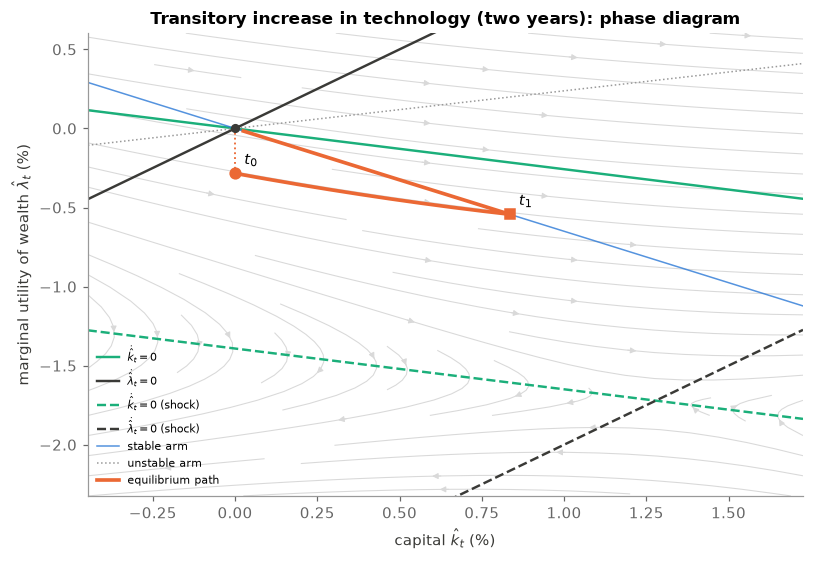

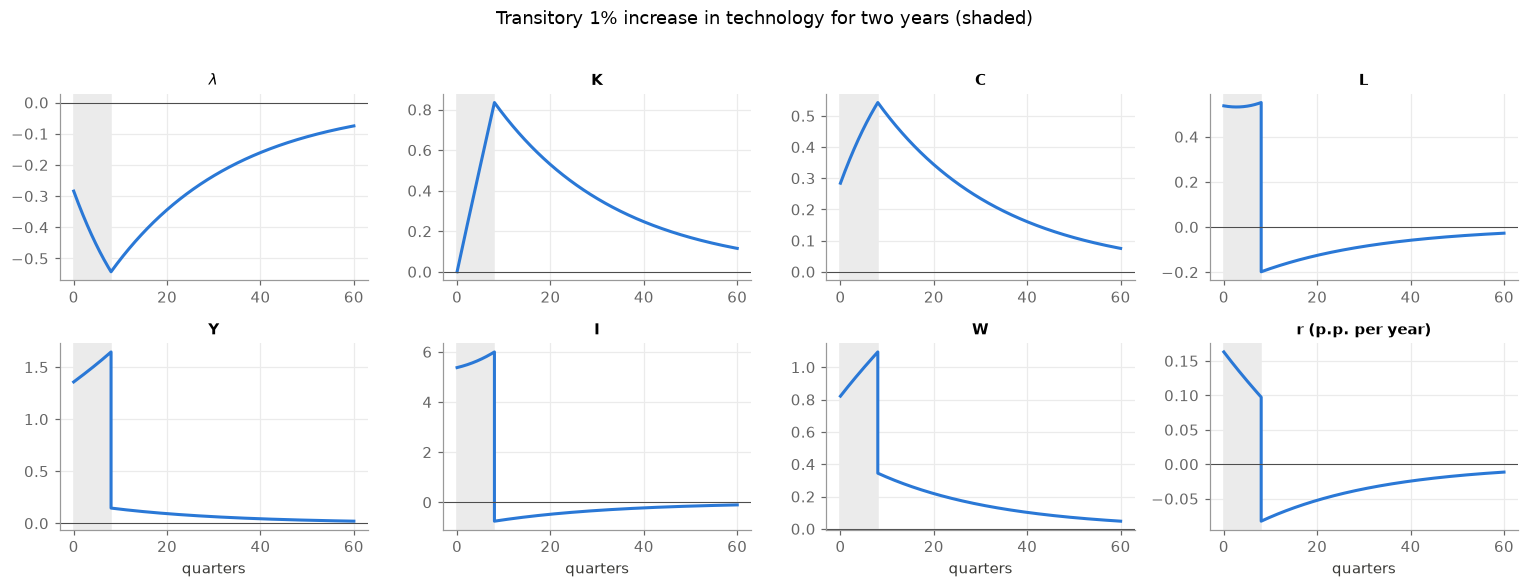

In [13]:
path = rbc.irf_step(p, z0=z0, t1=t1, T=25, n=1001)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
rp.phase_diagram(ax, p, z_new=z0, g_new=0.0, path=path, t1=t1)
ax.set_title("Transitory increase in technology (two years): phase diagram"); ax.legend(loc="lower left", fontsize=7)
plt.tight_layout()
rp.irf_panel(path, "Z", t1=t1)
plt.suptitle("Transitory 1% increase in technology for two years (shaded)", y=1.02)
plt.tight_layout()

In [14]:
rp.sign_table(rbc.irf_step(p, z0=z0, t1=t1, T=400, n=8001), t1=t1)

,impact,transition I,at t1,transition II,steady state
λ,↓,↓,0,↑,0
K,0,↑,0,↓,0
C,↑,↑,0,↓,0
L,↑,↓ then ↑,↓,↑,0
Y,↑,↑,↓,↓,0
I,↑,↑,↓,↑,0
W,↑,↑,↓,↓,0
r,↑,↓,↓,↑,0


## 7. Recap

These qualitative predictions indicate which shocks could be an important source of business cycles. The table summarizes the correlations with output predicted by the model conditional on each type of shock, and those in the data (Lecture 1). Government spending shocks have trouble reproducing key correlations: for example, $\rho(C, Y)$ is negative conditional on these shocks but positive in the data. Technology shocks match better but have problems too. $\rho(L, Y)$ is potentially ambiguous: its sign depends on parameters, and the Frisch elasticity of labor supply is very important here. In addition, technology shocks produce highly procyclical wages, inconsistent with the weak cyclicality of wages in the data.

| | $\rho(Y, L)$ | $\rho(Y, C)$ | $\rho(Y, I)$ | $\rho(Y, W)$ |
|---|:-:|:-:|:-:|:-:|
| $Z$ shocks | ? | + | + | + |
| $G$ shocks | + | − | + (permanent), − (transitory) | − |
| Data | + | + | + | +, ≈ 0 |

## 8. Try it yourself

1. **Government spending and the Euler equation.** Why does government spending not enter the law of motion of marginal utility (LDOT)? What does this imply for the $\dot{\hat\lambda}_t = 0$ locus?
2. **Margins of adjustment.** Redo the permanent government spending experiment with `rbc.Params(sg=0.2, eta=4)` and `eta=0.25`. How does the household split the adjustment between consumption and hours? Relate your answer to the discussion of the three margins in Section 3.
3. **Duration and investment.** Using the right panel of the figure in Section 4, explain why impact investment changes sign exactly when $\hat\lambda_{t_0}$ crosses the shifted $\dot{\hat k}_t = 0$ locus. How does the threshold duration change with the Frisch elasticity?
4. **Hours after a permanent technology shock.** Verify that steady-state hours do not change after a permanent technology shock when `sg=0`. Explain why they fall slightly when government spending is fixed in levels.
5. **Resolving the question marks.** For which values of $\eta$ do hours rise during the transition after a permanent government spending shock? Use `rp.sign_table`.
6. **Smooth versus step shocks.** Lecture 2 used shocks that decay exponentially, `rbc.irf(p, z0=0.01, theta_z=theta)`. Compare the responses with a step shock of similar persistence. Which entries of the tables change, and why?

## Summary

- Marginal utility $\lambda_t$ is forward looking: transitory shocks move it little, permanent shocks a lot (the permanent income hypothesis). Labor supply shifts with $\lambda_t$; labor demand with technology and capital.
- The intratemporal condition implies that wages must be strongly procyclical when consumption and hours comove ([Barro and King, 1984](https://doi.org/10.2307/1883127)).
- In the phase diagram, the $\dot{\hat k}_t = 0$ locus slopes down and the $\dot{\hat\lambda}_t = 0$ locus slopes up. Government spending shifts only the first; technology shifts both. $\lambda_t$ jumps onto the stable arm, or onto the explosive path that reaches the original stable arm when a transitory shock ends.
- Government spending shocks make consumption and output move in opposite directions, contrary to the data. Technology shocks generate the observed comovement, but with procyclical wages.
- Capital is the household's only means of saving: it smooths transitory shocks and propagates them over time.

**Next lecture.** We assess the model quantitatively: we simulate it with stochastic technology shocks and compare its second moments with the business cycle facts from Lecture 1.